# Vorlesungsnotebook zur Fourier Transformation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fftpack import fft, ifft, fftfreq, fftshift, ifftshift
from IPython.display import Audio


## Erzeugen eines 100Hz Tons

In [2]:
# sampling rate
sr = 4096
#t = np.arange(sr)
# sampling interval
ts = 1.0/sr
t = np.arange(0,1,ts)


freq = 100.
#x = 3*np.sin(2*np.pi*freq*t/sr)
x = 3*np.sin(2*np.pi*freq*t)



print(x.shape)


(4096,)


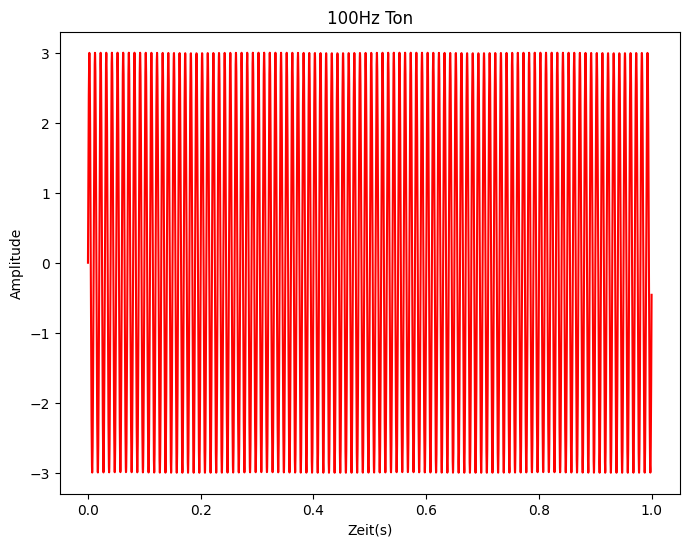

In [3]:
plt.figure(figsize = (8, 6))
plt.plot(t, x, 'r')
plt.ylabel('Amplitude')
plt.xlabel('Zeit(s)')
plt.title('100Hz Ton')

plt.show()

In [4]:
import numpy as np
from IPython.display import Audio
# Create the tone as a NumPy Sinus Wave
#wave = 6000*np.sin(2*np.pi*440*np.arange(sr*2)/sr)
# Play the Sinus Wave (tone)
Audio(x, rate=sr, autoplay=False)

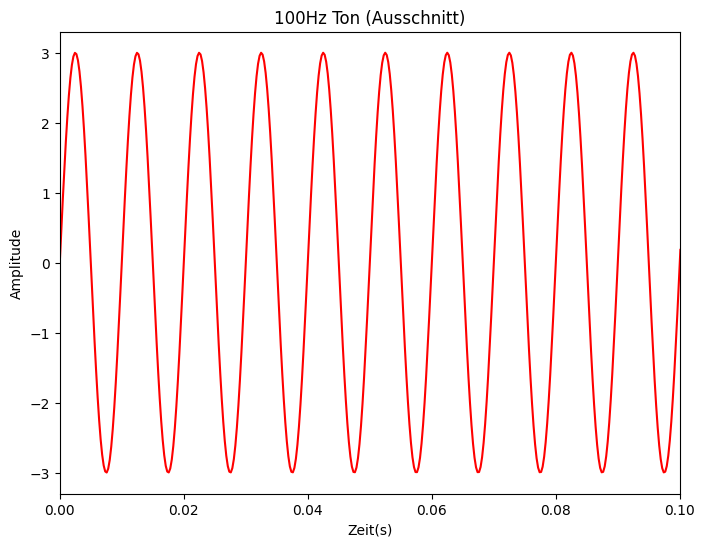

In [5]:
#t=np.arange(sr*2)
#print(t)
plt.figure(figsize = (8, 6))
plt.plot(t, x, 'r')
plt.xlim(0, 0.1)
plt.ylabel('Amplitude')
plt.xlabel('Zeit(s)')
plt.title('100Hz Ton (Ausschnitt)')

plt.show()

## Ton bestehende aus überlagerten Sinus-Schwingungen 

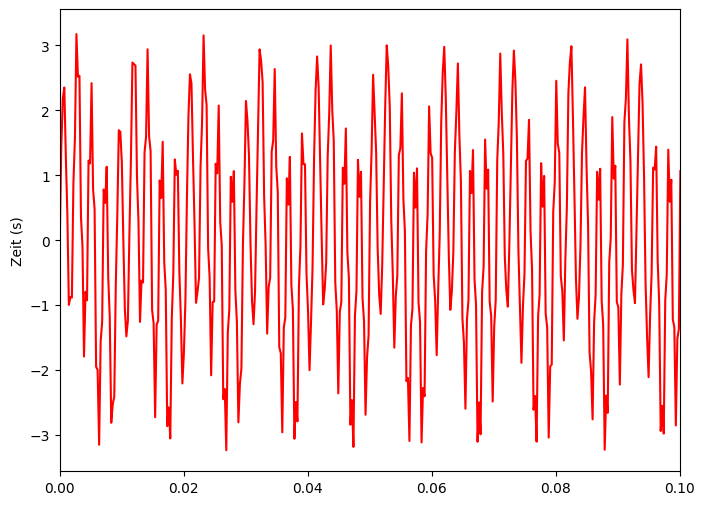

In [6]:


freq = 100
#x = np.sin(2*np.pi*freq*t/sr)
x = np.sin(2*np.pi*freq*t)


freq = 440
#x += 2*np.sin(2*np.pi*freq*t/sr)
x += 2*np.sin(2*np.pi*freq*t)

freq = 2000   
#x += 0.5* np.sin(2*np.pi*freq*t/sr)
x += 0.5* np.sin(2*np.pi*freq*t)

plt.figure(figsize = (8, 6))
plt.plot(t, x, 'r')
plt.xlim(0, 0.1)
plt.ylabel('Amplitude')
plt.ylabel('Zeit (s)')


plt.show()





In [7]:
Audio(x, rate=sr, autoplay=False)

## Implementierung der Diskreten Fourier Transformation

In [8]:

def DFT_naive(x):
    """Computes the Discrete Fourier Transform (DFT) of x

    Args:
        x: Array of sample values

    Returns:
        X: DFT of x
    """
    N = len(x)   
    n = np.arange(N)  #variiert
    
    X = list()

    # naive implementation of DFT 
   
    for k in range(N):
        Xk = 0.
        for n in range(N):
            Xk += x[n] * np.exp(-1j * k * n * 2 * np.pi / N)
        X.append(Xk)
    return X
    


In [9]:
#Berechnen der DFT auf dem Signal x 

X = DFT_naive(x)




In [10]:
X = DFT_naive(x)
X = np.asarray(X)
# calculate the frequency



Text(0, 0.5, 'DFT Amplitude |X(freq)|')

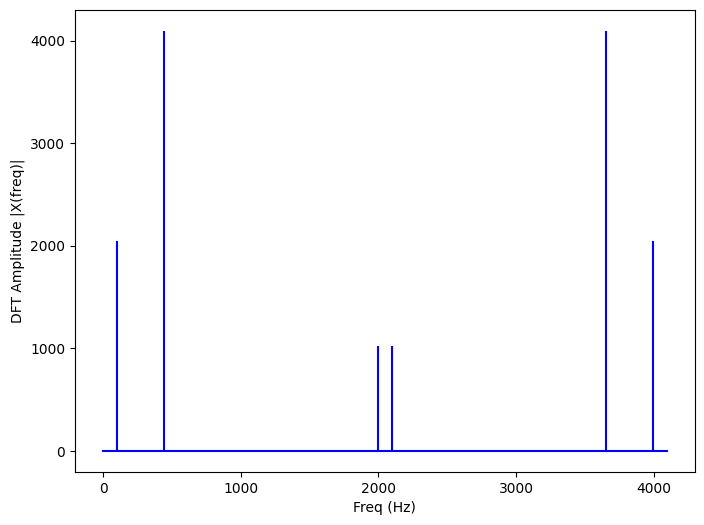

In [11]:
N = len(X)
n = np.arange(N)
T = N/sr
freq = n/T 


plt.figure(figsize = (8, 6))
plt.stem(freq, abs(X), 'b', \
         markerfmt=" ", basefmt="-b")
plt.xlabel('Freq (Hz)')
plt.ylabel('DFT Amplitude |X(freq)|')

### Abtasttheorem Nyquist-Shannon

Ein bandbegrenztes Signal $ f_{max} $ kann aus einer Folge von äquidistanten Abtastwerten exakt rekonstruiert werden, wenn es mit einer Frequenz von größer als $ 2*f_{max} $ abgetastet wurde. 

2048


Text(0, 0.5, 'DFT Amplitude |X(freq)|')

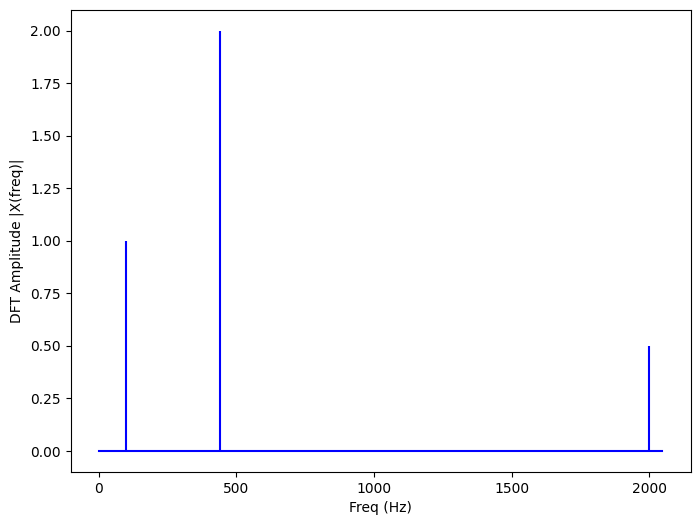

In [12]:
N = len(X)
n = np.arange(N)
T = N/sr
freq = n/T 

n_oneside = N//2

print(n_oneside)
# get the one side frequency
f_oneside = freq[:n_oneside]

# normalize the amplitude
X_oneside =X[:n_oneside]/n_oneside

plt.figure(figsize = (8, 6))
plt.stem(f_oneside, abs(X_oneside), 'b', \
         markerfmt=" ", basefmt="-b")
plt.xlabel('Freq (Hz)')
plt.ylabel('DFT Amplitude |X(freq)|')

In [13]:
#Finden der peaks
from scipy.signal import find_peaks
peaks, _ = find_peaks(abs(X), height=1)

freqs = [ i * sr / len(X) for i in peaks]

In [14]:
print(freqs[:len(freqs)//2])

[100.0, 440.0, 2000.0]


## DFT mit Matrizen

In [15]:
def DFT_vectorized(x):
    """
    Function to calculate the 
    discrete Fourier Transform 
    of a 1D real-valued signal x
    """

    x = np.asarray(x, dtype=float)
    N = x.shape[0]
    n = np.arange(N)
    k = n.reshape((N, 1))
   
    dftmat = np.exp(-2j * np.pi * k * n / N)
    
    X = np.dot(dftmat, x)
    
    return X

In [16]:
X_mat = DFT_vectorized(x)

print(X_mat.shape)

(4096,)


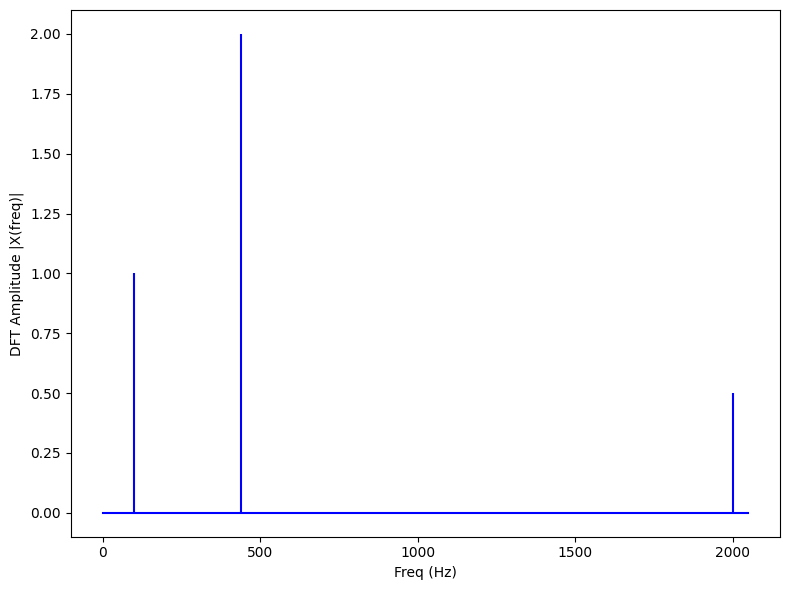

In [17]:
n_oneside = N//2
# get the one side frequency
f_oneside = freq[:n_oneside]

# normalize the amplitude
X_oneside =X_mat[:n_oneside]/n_oneside

plt.figure(figsize = (8, 6))
plt.stem(f_oneside, abs(X_oneside), 'b', \
         markerfmt=" ", basefmt="-b")
plt.xlabel('Freq (Hz)')
plt.ylabel('DFT Amplitude |X(freq)|')

plt.tight_layout()
plt.show()

## Laufzeitvergleich DFT loop und via Matrix

In [18]:
def gen_sig(sr):
    '''
    function to generate
    a simple 1D signal with
    different sampling rate
    '''
    ts = 1.0/sr
    t = np.arange(0,1,ts)

    freq = 1.
    x = 3*np.sin(2*np.pi*freq*t)
    return x

In [19]:
# sampling rate =2000
#sr = 2000

print("\nTiming of naive implementation:")
%time DFT_naive(gen_sig(sr))
print("---\nTiming of vectorized implementation:")
%time DFT_vectorized(gen_sig(sr))
print("---")


Timing of naive implementation:
CPU times: user 10.4 s, sys: 343 ms, total: 10.8 s
Wall time: 10.2 s
---
Timing of vectorized implementation:
CPU times: user 319 ms, sys: 75.5 ms, total: 395 ms
Wall time: 313 ms
---


In [20]:

sr = 8192

print("\nTiming of naive implementation:")
%time DFT_naive(gen_sig(sr))
print("---\nTiming of vectorized implementation:")
%time DFT_vectorized(gen_sig(sr))
print("---")


Timing of naive implementation:
CPU times: user 40.9 s, sys: 1.29 s, total: 42.2 s
Wall time: 40.8 s
---
Timing of vectorized implementation:
CPU times: user 1.15 s, sys: 852 ms, total: 2 s
Wall time: 1.96 s
---


## Schnelle Fourier-Transformation

In [21]:
def generate_dft_matrix(N):
    #Generates a DFT (discrete Fourier transfrom) matrix


    n = np.arange(N)
    k = n.reshape((N, 1))
   
    dftmat = np.exp(-2j * np.pi * k * n / N)
    
    return dftmat

### Visualisieren der FFT-Matrix

<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:12: SyntaxWarning: invalid escape sequence '\m'
<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:12: SyntaxWarning: invalid escape sequence '\m'
/var/folders/pb/9z396mvn5h50lm97gx3bv0j00000gn/T/ipykernel_83145/2735985033.py:5: SyntaxWarning: invalid escape sequence '\m'
  plt.title('$\mathrm{Re}(\mathrm{DFT}_{32})$')
/var/folders/pb/9z396mvn5h50lm97gx3bv0j00000gn/T/ipykernel_83145/2735985033.py:12: SyntaxWarning: invalid escape sequence '\m'
  plt.title('$\mathrm{Im}(\mathrm{DFT}_{32})$')


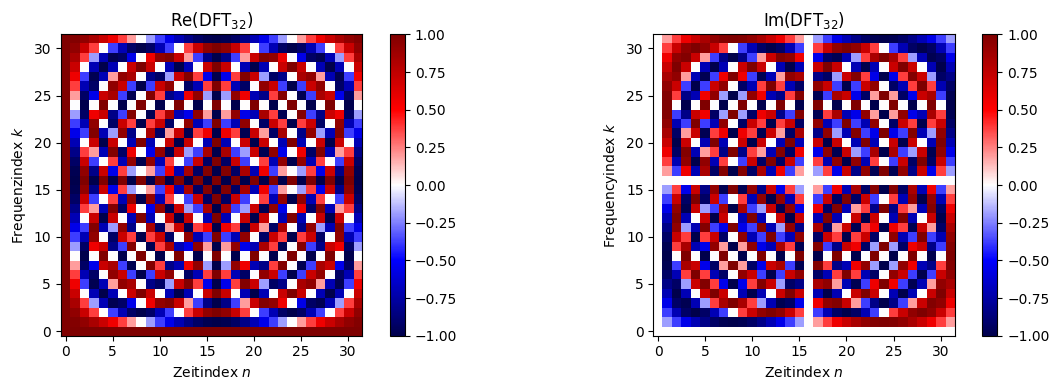

In [22]:
dft_mat = generate_dft_matrix(32)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.title('$\mathrm{Re}(\mathrm{DFT}_{32})$')
plt.imshow(np.real(dft_mat), origin='lower', cmap='seismic', aspect='equal')
plt.xlabel('Zeitindex $n$')
plt.ylabel('Frequenzindex $k$')
plt.colorbar()

plt.subplot(1, 2, 2)
plt.title('$\mathrm{Im}(\mathrm{DFT}_{32})$')
plt.imshow(np.imag(dft_mat), origin='lower', cmap='seismic', aspect='equal')
plt.xlabel('Zeitindex $n$')
plt.ylabel('Frequencyindex $k$')
plt.colorbar()
plt.tight_layout()

### Implementierung der FFT

In [28]:


def FFT(x):
    """Compute the fast Fourier transform (FFT)

    Notebook: C2/C2_DFT-FFT.ipynb

    Args:
        x (np.ndarray): Signal to be transformed

    Returns:
        X (np.ndarray): Fourier transform of x
    """
    x = x.astype(np.complex128)
    N = len(x)
    log2N = np.log2(N)
    assert log2N == int(log2N), 'N must be a power of two!'
    X = np.zeros(N, dtype=np.complex128)

    if N == 1:
        return x
    else:
        this_range = np.arange(N)
        Xe = FFT(x[::2])
        Xo = FFT(x[1::2])
        
        k = np.arange(N // 2)
        factor = np.exp(-2j * np.pi * k / N)
        
        fXo = factor * Xo
        X[:N//2] = Xe + fXo
        X[N//2:] = Xe - fXo
        X = np.concatenate(
            [X[:N//2],X[N//2:]])
        return X

In [29]:

sr = 8192

%time FFT(gen_sig(sr))

print("---")

CPU times: user 88.4 ms, sys: 3.43 ms, total: 91.9 ms
Wall time: 89.7 ms
---


In [30]:
X_fft = FFT(x)

Text(0, 0.5, 'DFT Amplitude |X(freq)|')

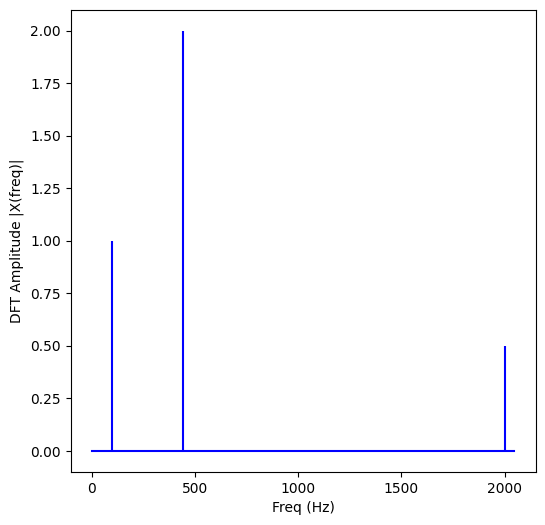

In [31]:
n_oneside = N//2
# get the one side frequency
f_oneside = freq[:n_oneside]

# normalize the amplitude
X_oneside =X_fft[:n_oneside]/n_oneside

plt.figure(figsize = (6, 6))
plt.stem(f_oneside, abs(X_oneside), 'b', \
         markerfmt=" ", basefmt="-b")
plt.xlabel('Freq (Hz)')
plt.ylabel('DFT Amplitude |X(freq)|')



## Ende

In [32]:
def FFT(x):
    """
    A recursive implementation of 
    the 1D Cooley-Tukey FFT, the 
    input should have a length of 
    power of 2. 
    """
    N = len(x)
    
    if N == 1:
        return x
    else:
        X_even = FFT(x[::2])
        X_odd = FFT(x[1::2])
        factor = \
          np.exp(-2j*np.pi*np.arange(N)/ N)
                
        X = np.concatenate(\
            [X_even+factor[:int(N/2)]*X_odd,
             X_even+factor[int(N/2):]*X_odd])
        return X